# 02 · Hyper-parameter optimisation (Optuna)

One study per architecture, run on the **E1 setting** (1,000 balanced real images from A, no augmentation).

| | |
|---|---|
| Objective | best **validation BCE** on A-validation (682 images). AUROC saturates at ≈0.99 on A and cannot rank configurations; BCE is a proper scoring rule that still separates them |
| Sampler | TPE (multivariate, seed 0, 8 random start-up trials) |
| Pruner | median pruner on the validation-loss curve (after 300 steps, 6 start-up trials) |
| Budget per trial | ≤1,500 steps, evaluation every 50 steps, early stopping after 8 evaluations without improvement |
| Search space | lr [1e-5, 1e-3] log · weight decay [1e-4, 0.2] log · batch {16, 32, 64} · schedule {cosine, plateau} · warm-up {0..200} · head-LR ×{1, 10} · label smoothing [0, 0.1] · dropout [0, 0.5] · stochastic depth [0, 0.3] |
| Seed | 0 (the final runs use seeds 0, 1, 2 with the selected parameters) |

The external dataset B is **never** used here. The selected parameters are then frozen for every experiment (E1–E4 and the controls), so data is the only variable.

### How the search works (short primer)
* **TPE (Tree-structured Parzen Estimator).** After a few random trials, Optuna splits past trials into "good" and "bad" by objective value. It models the parameter distribution of each group and proposes new points where good/bad density is high. This is far more sample-efficient than grid search, and it handles log-scale, categorical and conditional parameters (e.g. stochastic depth only for architectures that support it).
* **Median pruning.** Each trial reports its validation loss every 50 steps. After 300 steps, a trial whose loss is worse than the median of earlier trials *at the same step* is stopped. Most bad configurations are obvious early, so pruning spends GPU time on promising ones. A pruned trial's last value is shown in grey in the history plots.
* **Why BCE and not AUROC?** On A-validation every reasonable model scores AUROC ≈0.99 (the acquisition shortcut, notebook 01), so AUROC differences between trials are noise. BCE (log-loss) also rewards confident, correct, well-ranked predictions, and it keeps decreasing when AUROC is already saturated.
* **Why tune per architecture?** CNNs and transformers prefer very different learning rates and regularisation. Comparing architectures with one shared setting would mostly compare how well that setting suits each one.

### Caveats
* One seed per trial: the objective is noisy (seed-to-seed spread of val BCE ≈0.01). Small differences between the top trials are not meaningful, and TPE's pick is "one of the good configurations", not "the optimum".
* The objective is A-validation, which shares A's shortcut. HPO optimises in-domain fit; it cannot optimise external generalisation (doing so would require B, which is reserved for testing).
* 25 trials per architecture is a modest budget for 8–9 dimensions. The importance analysis below is indicative, not definitive.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "reports/results"; RES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40)

import optuna
from optuna.trial import TrialState
optuna.logging.set_verbosity(optuna.logging.WARNING)
from cxr.models import ARCHS
STORAGE = f"sqlite:///{ROOT / 'artifacts/optuna/optuna.db'}"
studies = {s.study_name.removeprefix("hpo_"): optuna.load_study(study_name=s.study_name, storage=STORAGE)
           for s in optuna.get_all_study_summaries(STORAGE)}
studies = {a: studies[a] for a in ARCHS if a in studies}
print("studies:", list(studies))

/home/edelweizse/Projects/uni/AIE/final/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


studies: ['resnet18', 'resnet50', 'densenet121', 'efficientnet_b0', 'convnext_tiny', 'vit_small', 'swin_tiny']


## Summary per architecture

In [2]:
rows = []
for arch, st in studies.items():
    trials = st.get_trials(deepcopy=False)
    done = [t for t in trials if t.state == TrialState.COMPLETE]
    best = st.best_trial
    rows.append({"arch": arch, "complete": len(done), "pruned": sum(t.state == TrialState.PRUNED for t in trials),
                 "failed": sum(t.state == TrialState.FAIL for t in trials),
                 "best_val_bce": best.value, "best_val_auroc": best.user_attrs.get("best_val_auroc"),
                 "median_val_bce": np.median([t.value for t in done]),
                 "gpu_minutes": sum(t.user_attrs.get("train_time_s", 0) for t in done) / 60,
                 **{f"p:{k}": v for k, v in best.params.items()}})
hpo = pd.DataFrame(rows).set_index("arch")
hpo.to_csv(RES / "hpo_summary.csv")
display(hpo.round(4))

,complete,pruned,failed,best_val_bce,best_val_auroc,median_val_bce,gpu_minutes,p:lr,p:weight_decay,p:batch_size,p:schedule,p:warmup_steps,p:head_lr_mult,p:label_smoothing,p:drop_rate,p:drop_path_rate
arch,,,,,,,,,,,,,,,,
resnet18,13,12,0,0.0646,0.9963,0.0796,13.3052,0.0007,0.0001,64,plateau,100,1.0,0.0323,0.3744,0.0470
resnet50,20,5,0,0.0464,0.9985,0.0722,33.0853,0.0008,0.0047,32,plateau,50,10.0,0.0047,0.0789,0.1838
densenet121,19,6,0,0.0378,0.9991,0.0480,27.3003,0.0006,0.0231,16,plateau,150,10.0,0.0111,0.0857,NaN
efficientnet_b0,17,8,0,0.0342,0.9995,0.0603,20.9628,0.0009,0.0004,64,plateau,0,1.0,0.0324,0.1280,0.1559
convnext_tiny,15,10,0,0.0555,0.9949,0.0756,24.7835,0.0002,0.0002,64,cosine,200,10.0,0.0335,0.3131,0.1865
vit_small,21,4,0,0.0663,0.9936,0.0926,20.1223,0.0000,0.0012,32,cosine,150,1.0,0.0375,0.3280,0.0457
swin_tiny,21,4,0,0.0689,0.9982,0.0813,42.1770,0.0001,0.0016,32,plateau,50,10.0,0.0400,0.4481,0.0775


## Optimisation history

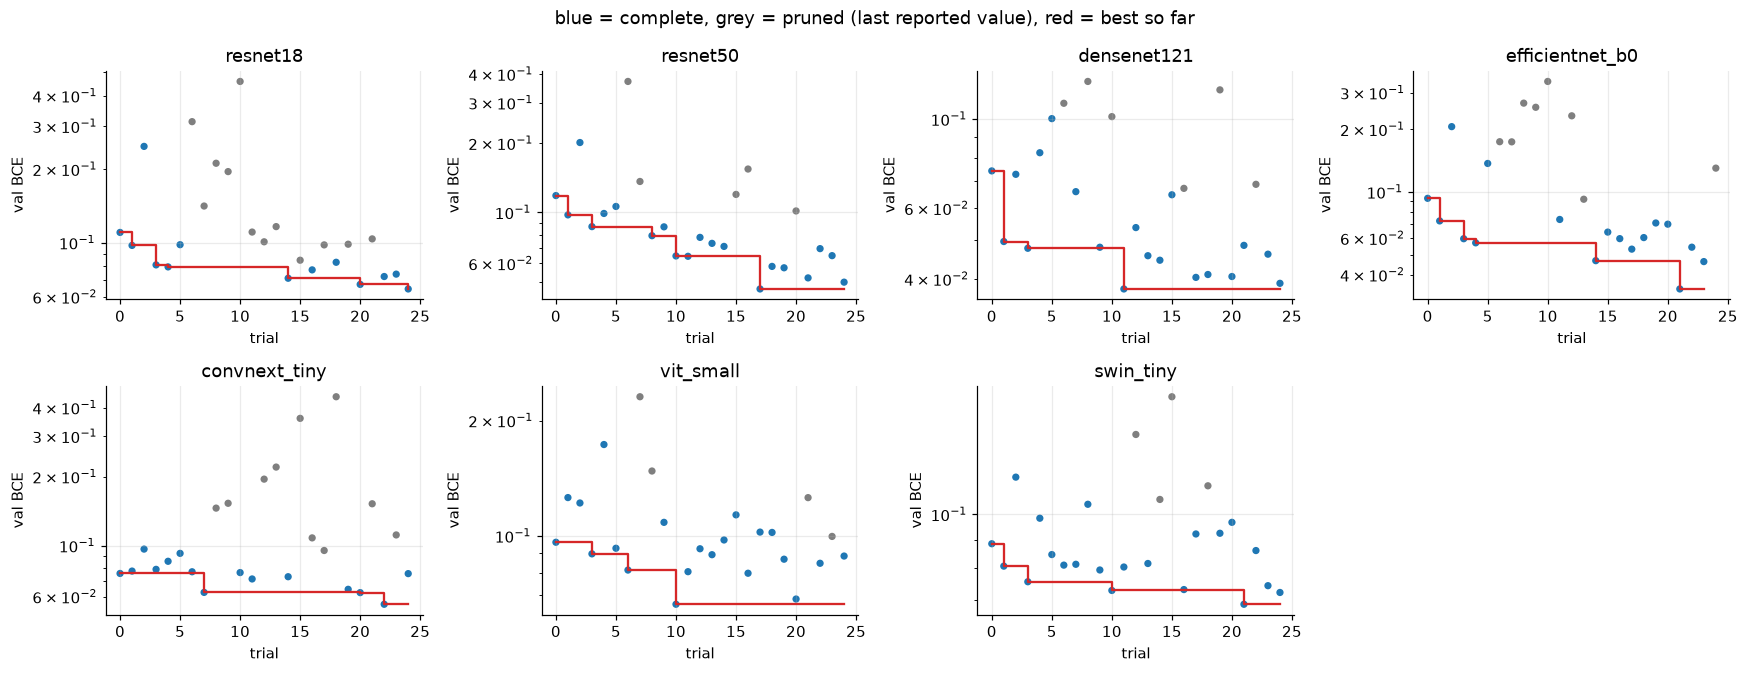

In [3]:
n = len(studies); cols = 4; rows_ = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows_, cols, figsize=(4 * cols, 3.1 * rows_), squeeze=False)
for ax, (arch, st) in zip(axes.flat, studies.items()):
    ts = [t for t in st.get_trials(deepcopy=False) if t.value is not None]
    num = [t.number for t in ts]; val = [t.value for t in ts]
    col = ["tab:blue" if t.state == TrialState.COMPLETE else "tab:gray" for t in ts]
    ax.scatter(num, val, c=col, s=14)
    comp = sorted((t.number, t.value) for t in ts if t.state == TrialState.COMPLETE)
    if comp:
        ax.step([c[0] for c in comp], np.minimum.accumulate([c[1] for c in comp]), where="post", color="tab:red")
    ax.set_title(arch); ax.set_yscale("log"); ax.set_xlabel("trial"); ax.set_ylabel("val BCE")
for ax in list(axes.flat)[n:]: ax.axis("off")
fig.suptitle("blue = complete, grey = pruned (last reported value), red = best so far")
plt.tight_layout(); plt.savefig(FIG / "hpo_history.png", bbox_inches="tight"); plt.show()

## Which hyper-parameters matter? (fANOVA importance per architecture)

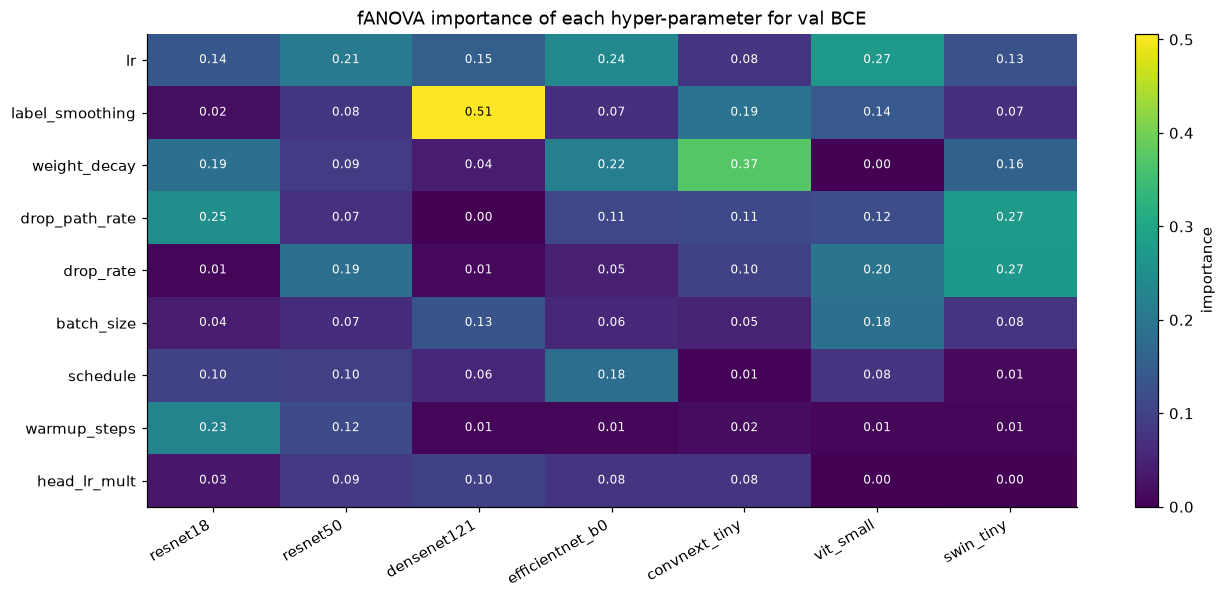

In [4]:
imp = {}
for arch, st in studies.items():
    if len(st.get_trials(states=(TrialState.COMPLETE,))) >= 5:
        imp[arch] = optuna.importance.get_param_importances(st, evaluator=optuna.importance.FanovaImportanceEvaluator(seed=0))
imp = pd.DataFrame(imp).fillna(0)
imp = imp.loc[imp.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(1.3 * len(imp.columns) + 3, 0.45 * len(imp) + 1.5))
im = ax.imshow(imp.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(imp.columns)), imp.columns, rotation=30, ha="right"); ax.set_yticks(range(len(imp)), imp.index)
for i in range(imp.shape[0]):
    for j in range(imp.shape[1]):
        ax.text(j, i, f"{imp.values[i, j]:.2f}", ha="center", va="center", color="w" if imp.values[i, j] < 0.5 else "k", fontsize=8)
ax.grid(False); plt.colorbar(im, label="importance"); plt.title("fANOVA importance of each hyper-parameter for val BCE")
plt.tight_layout(); plt.savefig(FIG / "hpo_importance.png", bbox_inches="tight"); plt.show()

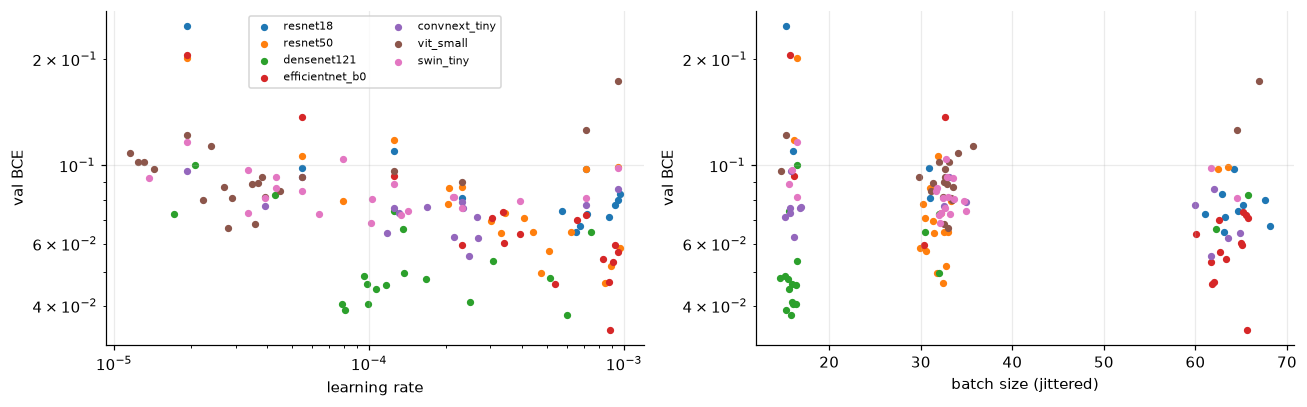

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for arch, st in studies.items():
    ts = [t for t in st.get_trials(deepcopy=False) if t.state == TrialState.COMPLETE]
    axes[0].scatter([t.params["lr"] for t in ts], [t.value for t in ts], s=14, label=arch)
    axes[1].scatter([t.params["batch_size"] * (1 + 0.04 * np.random.randn()) for t in ts], [t.value for t in ts], s=14)
axes[0].set_xscale("log"); axes[0].set_xlabel("learning rate"); axes[1].set_xlabel("batch size (jittered)")
for ax in axes: ax.set_yscale("log"); ax.set_ylabel("val BCE")
axes[0].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.savefig(FIG / "hpo_lr_batch.png", bbox_inches="tight"); plt.show()

**How to read these plots**
* *History*: each dot is a trial. The red step line is the best value found so far. A curve that flattens early means later trials rarely beat the early best: the search converged, or the remaining differences are within seed noise.
* *fANOVA importance*: the share of variance in val BCE explained by each parameter, from a random-forest surrogate fitted on the completed trials. High importance means "getting this one right matters"; it does not say which direction is good. Check the scatter plots for that.
* *LR scatter*: the U-shape typical of fine-tuning. Too low a learning rate under-fits within the step budget; too high a rate destroys pretrained features (transformers are usually more sensitive).

## Insights from the search

**1. CNNs and transformers want learning rates ~30× apart.** The best LRs are 6–9·10⁻⁴ for the CNNs (ResNet-18/50, DenseNet-121, EfficientNet-B0), 2.5·10⁻⁴ for ConvNeXt-T, 1·10⁻⁴ for Swin-T and 2.8·10⁻⁵ for ViT-S. A single shared setting would have badly handicapped one family, so per-architecture tuning was necessary for a fair comparison.

**2. There is no universal "most important" hyper-parameter.** fANOVA importance is spread out and differs per architecture. Learning rate is consistently relevant (0.08–0.27). Weight decay matters for ConvNeXt (0.37), and label smoothing dominates DenseNet (0.51). Stochastic depth and dropout matter for Swin (0.27 each). With 25 noisy single-seed trials these numbers are indicative only.

**3. Reduce-on-plateau won for 5 of 7 architectures** (cosine for ConvNeXt and ViT). With early stopping on the same validation signal, plateau decay adapts to when the model stops improving, which with only 1,000 images happens after a few hundred steps.

**4. Validation AUROC cannot discriminate between configurations.** The best trials of all seven architectures score 0.994–0.9995. BCE separates them (0.034 → 0.069). EfficientNet-B0 (0.034) and DenseNet-121 (0.038) fit A best; the transformers are worst (ViT 0.066, Swin 0.069), as expected for weaker-inductive-bias models with 1,000 training images.

**5. The searches had not fully converged.** For most architectures the first trial within 5% of the final best came late (trials 17–22 of 25). More trials could still lower val BCE somewhat. But notebook 03 shows that lower A-validation loss does not reliably buy external performance, so a bigger search would mostly sharpen in-domain fit.

**6. Pruning was effective.** 4–12 of 25 trials per architecture were stopped early. A whole 25-trial study took 13–42 GPU-minutes, about 3 GPU-hours for all seven.